In [1]:
%pip install pandas numpy scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
"""
Smart Grid Power Quality Anomaly Detection - BASIC Isolation Forest model
Dataset: High-resolution power quality and voltage monitoring dataset
         (Train_Data.csv ~16MB, Test_Data.csv ~14MB, London Met repository)

Usage:
    1. Put Train_Data.csv and Test_Data.csv in the same folder as this script.
    2. pip install pandas numpy scikit-learn matplotlib
    3. python basic_isolation_forest.py

If the label column or the "normal" class is guessed wrongly, set
LABEL_COL and NORMAL_VALUES below.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

# ----------------------------------------------------------------------
# 0. SETTINGS (edit if needed)
# ----------------------------------------------------------------------
TRAIN_FILE = "Train_Data.csv"
TEST_FILE = "Test_Data.csv"

LABEL_COL = None        # e.g. "Disturbance" ; None = auto-detect
NORMAL_VALUES = None    # e.g. ["Normal"] or [0] ; None = most frequent class
RANDOM_STATE = 42


In [3]:
# ----------------------------------------------------------------------
# 1. LOAD DATA
# ----------------------------------------------------------------------
train = pd.read_csv(TRAIN_FILE)
test = pd.read_csv(TEST_FILE)

# remove extra spaces from column names
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("\nColumns:", list(train.columns))
print("\nFirst rows:\n", train.head())
missing = train.isnull().sum()
print("\nMissing values (train):\n", missing[missing > 0])

Train shape: (256295, 10)
Test shape : (230419, 10)

Columns: ['Start Date and Time', 'Upstream Voltage Min(kV)', 'Upstream Voltage Avg(kV)', 'Upstream Voltage Max(kV)', 'Downstream Voltage Avg(V)', 'Downstream Voltage Max(V)', 'THD-V Min(%)', 'THD-V Avg(%)', 'THD-V Max(%)', 'Disturbance Type']

First rows:
   Start Date and Time  Upstream Voltage Min(kV)  Upstream Voltage Avg(kV)  \
0    01-01-2023 00:00                     18.53                     18.64   
1    01-01-2023 00:01                     18.54                     18.64   
2    01-01-2023 00:02                     18.54                     18.64   
3    01-01-2023 00:03                     18.51                     18.63   
4    01-01-2023 00:04                     18.50                     18.60   

   Upstream Voltage Max(kV)  Downstream Voltage Avg(V)  \
0                     18.81                      78.51   
1                     18.78                      78.55   
2                     18.77                      78.6

In [4]:
# ----------------------------------------------------------------------
# 2. FIND THE LABEL COLUMN
# ----------------------------------------------------------------------
def detect_label_column(df):
    keywords = ["label", "disturb", "class", "event", "target", "anomaly", "fault"]
    for col in df.columns:
        if any(k in col.lower() for k in keywords):
            return col
    return None


label_col = LABEL_COL or detect_label_column(train)
if label_col is None or label_col not in train.columns:
    raise SystemExit(
        "Could not detect the label column. Set LABEL_COL at the top of the "
        "script to the correct column name from the list printed above."
    )

print(f"\nUsing label column: '{label_col}'")
print("Class distribution (train):\n", train[label_col].value_counts())


Using label column: 'Disturbance Type'
Class distribution (train):
 Disturbance Type
0    255964
2       159
3        73
4        53
1        46
Name: count, dtype: int64


In [5]:
# ----------------------------------------------------------------------
# 3. CREATE BINARY LABELS (0 = normal, 1 = anomaly)
# ----------------------------------------------------------------------
if NORMAL_VALUES is None:
    normal_values = [train[label_col].value_counts().idxmax()]
else:
    normal_values = NORMAL_VALUES

print("Treating these values as NORMAL:", normal_values)

y_train = (~train[label_col].isin(normal_values)).astype(int)
y_test = (~test[label_col].isin(normal_values)).astype(int)

print(f"Anomaly rate - train: {y_train.mean():.3%}, test: {y_test.mean():.3%}")

Treating these values as NORMAL: [np.int64(0)]
Anomaly rate - train: 0.129%, test: 0.247%


In [6]:
# ----------------------------------------------------------------------
# 4. SELECT NUMERIC FEATURES
# ----------------------------------------------------------------------
X_train = train.drop(columns=[label_col]).copy()
X_test = test.drop(columns=[label_col], errors="ignore").copy()

# try converting text columns (e.g. numbers stored as strings) to numeric
for df in (X_train, X_test):
    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = pd.to_numeric(df[col], errors="coerce")

# keep only columns that are numeric and not entirely empty in train
numeric_cols = [
    c for c in X_train.columns
    if c in X_test.columns
    and pd.api.types.is_numeric_dtype(X_train[c])
    and X_train[c].notna().any()
]
X_train = X_train[numeric_cols]
X_test = X_test[numeric_cols]

# fill missing values using the training median
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("\nFeatures used:", numeric_cols)



Features used: ['Upstream Voltage Min(kV)', 'Upstream Voltage Avg(kV)', 'Upstream Voltage Max(kV)', 'Downstream Voltage Avg(V)', 'Downstream Voltage Max(V)', 'THD-V Min(%)', 'THD-V Avg(%)', 'THD-V Max(%)']


In [7]:
# ----------------------------------------------------------------------
# 5. SCALE FEATURES
# ----------------------------------------------------------------------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [8]:
# ----------------------------------------------------------------------
# 6. BASIC ISOLATION FOREST (default parameters)
# ----------------------------------------------------------------------
model = IsolationForest(random_state=RANDOM_STATE)   # all defaults
model.fit(X_train_s)

# predictions: sklearn returns -1 for anomaly, 1 for normal -> convert to 1/0
pred_test = (model.predict(X_test_s) == -1).astype(int)

# anomaly score: higher = more anomalous
score_test = -model.decision_function(X_test_s)

In [9]:
# ----------------------------------------------------------------------
# 7. EVALUATION
# ----------------------------------------------------------------------
precision = precision_score(y_test, pred_test, zero_division=0)
recall = recall_score(y_test, pred_test, zero_division=0)
f1 = f1_score(y_test, pred_test, zero_division=0)
try:
    auc = roc_auc_score(y_test, score_test)
except ValueError:
    auc = float("nan")   # happens if test set has only one class

print("\n================ BASIC MODEL RESULTS ================")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {auc:.4f}")
print("\nConfusion matrix [rows=actual, cols=predicted]:")
print(confusion_matrix(y_test, pred_test, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(
    y_test, pred_test, labels=[0, 1],
    target_names=["Normal", "Anomaly"], zero_division=0,
))

# save results so you can compare with the optimised model later
pd.DataFrame([{
    "model": "Basic IsolationForest",
    "precision": precision, "recall": recall, "f1": f1, "roc_auc": auc,
}]).to_csv("basic_model_results.csv", index=False)



================ BASIC MODEL RESULTS ================
Precision : 0.0040
Recall    : 0.4544
F1-score  : 0.0079
ROC-AUC   : 0.5806

Confusion matrix [rows=actual, cols=predicted]:
[[164959  64890]
 [   311    259]]

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.72      0.83    229849
     Anomaly       0.00      0.45      0.01       570

    accuracy                           0.72    230419
   macro avg       0.50      0.59      0.42    230419
weighted avg       1.00      0.72      0.83    230419



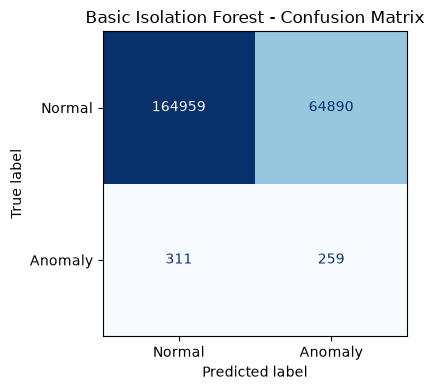

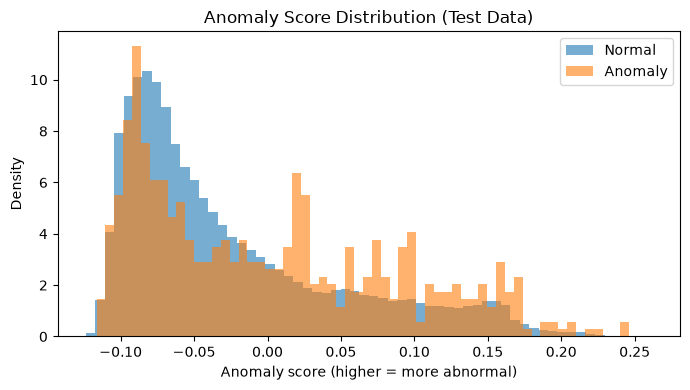


Saved: basic_model_results.csv, basic_confusion_matrix.png, basic_score_distribution.png


In [10]:
# ----------------------------------------------------------------------
# 8. PLOTS
# ----------------------------------------------------------------------
# (a) confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=[0, 1], display_labels=["Normal", "Anomaly"],
    cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title("Basic Isolation Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig("basic_confusion_matrix.png", dpi=150)

# (b) anomaly score distribution
plt.figure(figsize=(7, 4))
plt.hist(score_test[y_test.values == 0], bins=60, alpha=0.6, label="Normal", density=True)
plt.hist(score_test[y_test.values == 1], bins=60, alpha=0.6, label="Anomaly", density=True)
plt.xlabel("Anomaly score (higher = more abnormal)")
plt.ylabel("Density")
plt.title("Anomaly Score Distribution (Test Data)")
plt.legend()
plt.tight_layout()
plt.savefig("basic_score_distribution.png", dpi=150)

plt.show()
print("\nSaved: basic_model_results.csv, basic_confusion_matrix.png, "
      "basic_score_distribution.png")